In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [13]:
DATA_PATH = Path("../data/processed/train.csv")

In [14]:
df = pd.read_csv(DATA_PATH)

In [15]:
df.head()

,vehicle_speed,leader_speed,leader_distance,relative_speed,time_to_collision,speed_limit,target_speed
0,19.66,0.87,2.73,18.79,0.15,22.22,0.00
1,10.71,9.09,47.24,1.62,29.16,22.22,11.27
2,10.83,18.07,89.49,-7.24,99.00,16.67,13.00
3,4.33,17.84,99.20,-13.51,99.00,16.67,6.35
4,5.23,8.04,41.01,-2.81,99.00,22.22,8.10


In [16]:
df.shape

(4000, 7)

In [17]:
print(df.isnull().sum())
print(df.dtypes)
df.describe().T

vehicle_speed        0
leader_speed         0
leader_distance      0
relative_speed       0
time_to_collision    0
speed_limit          0
target_speed         0
dtype: int64
vehicle_speed        float64
leader_speed         float64
leader_distance      float64
relative_speed       float64
time_to_collision    float64
speed_limit          float64
target_speed         float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
vehicle_speed,4000.0,9.770155,6.243343,0.00,4.5800,9.300,14.1000,25.64
leader_speed,4000.0,9.995807,6.937554,0.00,2.8100,9.910,16.3500,25.65
leader_distance,4000.0,32.518615,28.336822,0.50,7.8200,23.175,49.3300,101.43
relative_speed,4000.0,-0.225555,9.214529,-24.39,-7.0525,-0.315,6.2000,24.32
time_to_collision,4000.0,54.835957,47.271833,0.10,1.9500,99.000,99.0000,99.00
speed_limit,4000.0,19.456118,4.401894,13.89,13.8900,22.220,25.0000,25.00
target_speed,4000.0,6.102300,5.918496,0.00,0.0000,4.910,9.9325,24.58


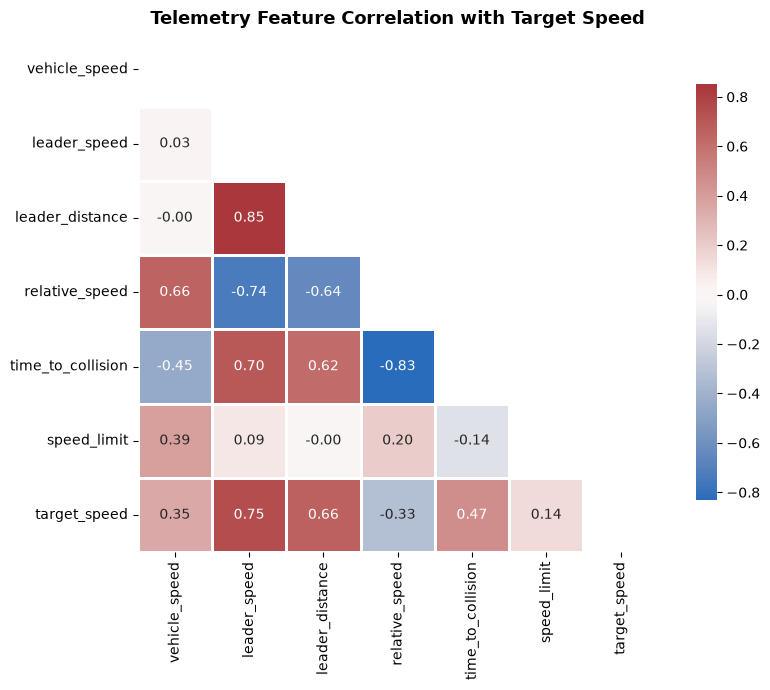

In [18]:
plt.figure(figsize=(9, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="vlag", 
    center=0,
    square=True, 
    linewidths=0.8,
    cbar_kws={"shrink": 0.8}
)
plt.title("Telemetry Feature Correlation with Target Speed", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()

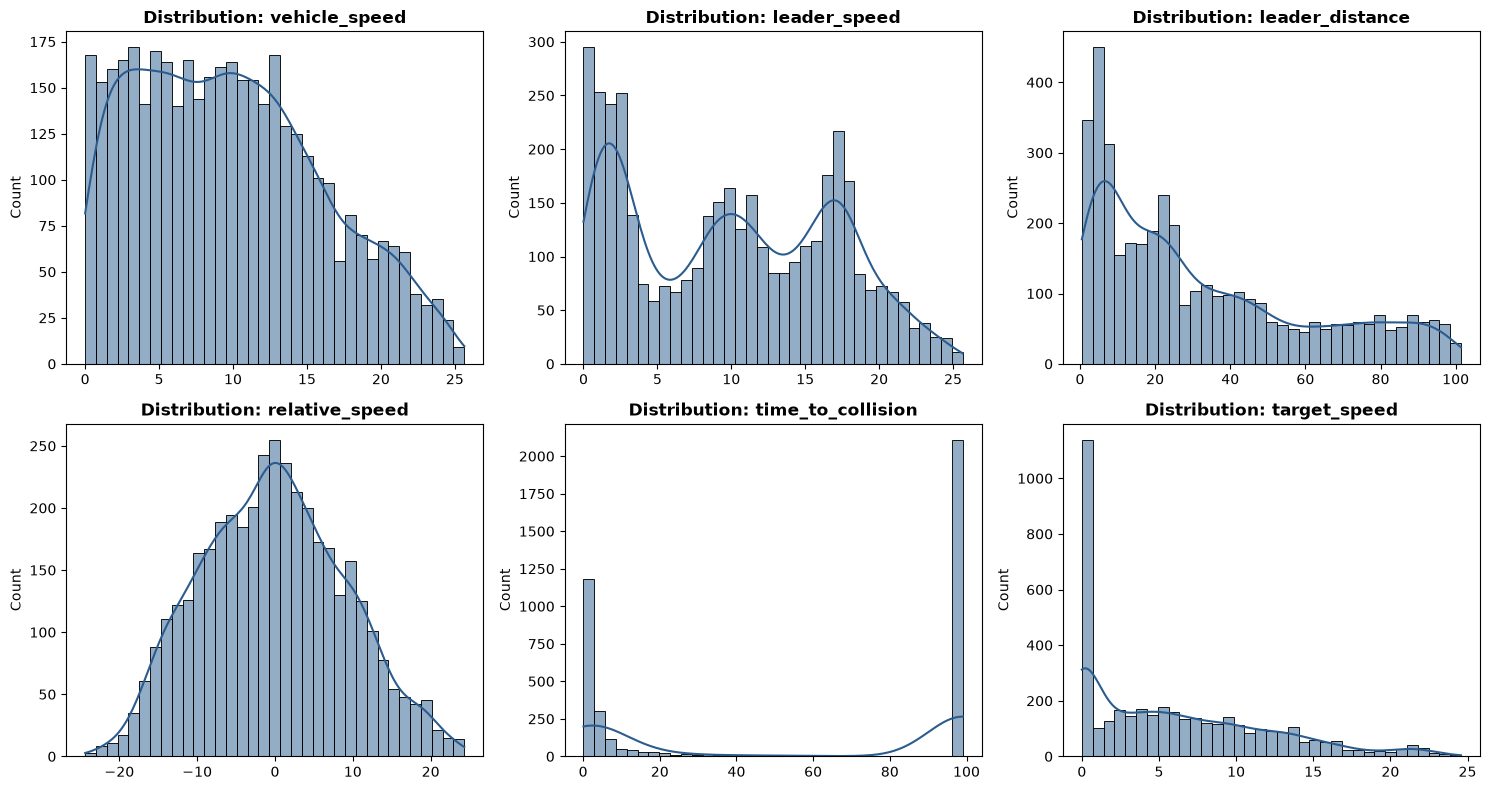

In [19]:
features = [
    "vehicle_speed", "leader_speed", "leader_distance", 
    "relative_speed", "time_to_collision", "target_speed"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=35, color="#2b5c8f")
    axes[i].set_title(f"Distribution: {col}", weight="bold")
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

Total Emergency Braking Samples: 1277


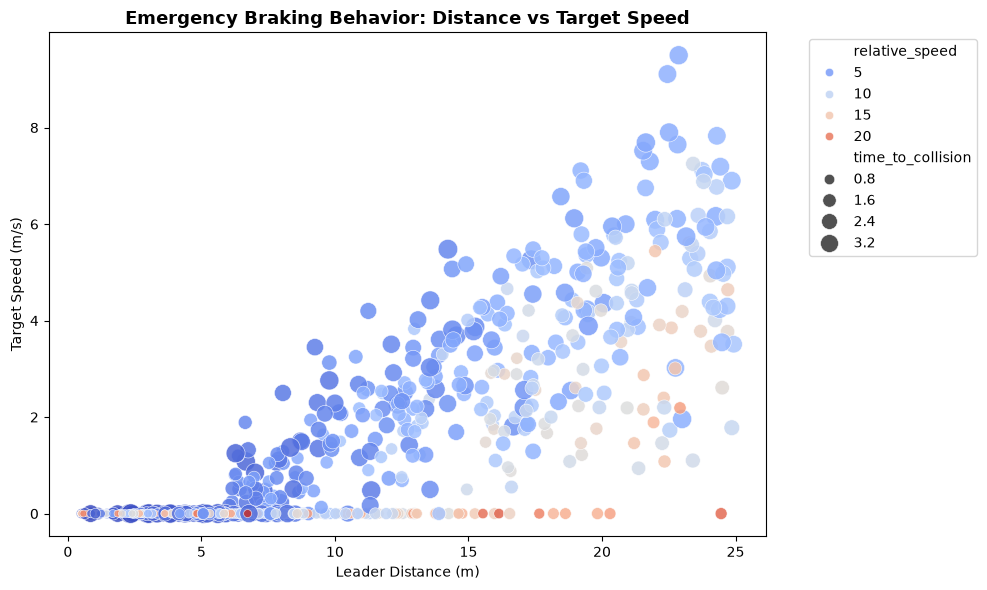

In [20]:
# Emergency braking zone filter (TTC < 4s & Distance < 25m)
emergency_mask = (df["time_to_collision"] < 4.0) & (df["leader_distance"] < 25.0)
emergency_samples = df[emergency_mask]

print(f"Total Emergency Braking Samples: {len(emergency_samples)}")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=emergency_samples,
    x="leader_distance",
    y="target_speed",
    hue="relative_speed",
    palette="coolwarm",
    size="time_to_collision",
    sizes=(25, 200),
    alpha=0.85
)
plt.title("Emergency Braking Behavior: Distance vs Target Speed", fontsize=13, weight="bold")
plt.xlabel("Leader Distance (m)")
plt.ylabel("Target Speed (m/s)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

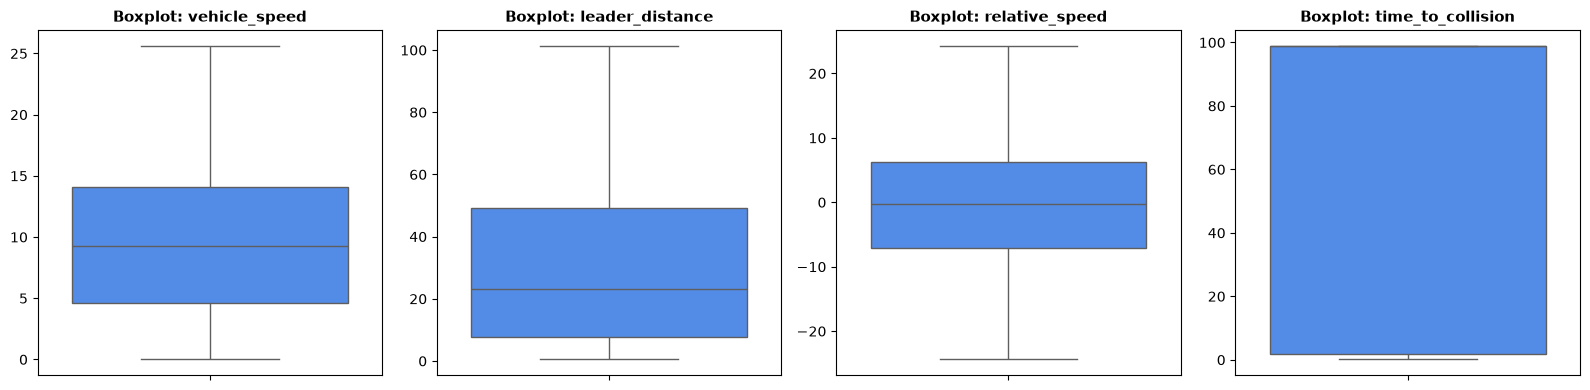

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
box_cols = ["vehicle_speed", "leader_distance", "relative_speed", "time_to_collision"]

for i, col in enumerate(box_cols):
    sns.boxplot(
        y=df[col], 
        ax=axes[i], 
        color="#3a86ff", 
        flierprops=dict(markerfacecolor='crimson', markersize=4, alpha=0.5)
    )
    axes[i].set_title(f"Boxplot: {col}", weight="bold", fontsize=11)
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()